C:\Users\shrey\AppData\Roaming\Python\Python313\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.0.post2)/charset_normalizer (3.4.3) doesn't match a supported version!
  warnings.warn(


Epoch 1/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 9s 22ms/step - accuracy: 0.5603 - loss: 1.6491 - val_accuracy: 0.8609 - val_loss: 0.6024
Epoch 2/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9105 - loss: 0.3844 - val_accuracy: 0.9536 - val_loss: 0.2250
Epoch 3/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 21ms/step - accuracy: 0.9786 - loss: 0.1446 - val_accuracy: 0.9945 - val_loss: 0.0865
Epoch 4/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9964 - loss: 0.0620 - val_accuracy: 0.9998 - val_loss: 0.0387
Epoch 5/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9995 - loss: 0.0304 - val_accuracy: 1.0000 - val_loss: 0.0219
Epoch 6/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.9999 - loss: 0.0180 - val_accuracy: 1.0000 - val_loss: 0.0134
Epoch 7/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 1.0000 - loss: 0.0112 - val_accuracy: 0.9996 - val_loss: 0.0120
Epoch 8/10
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step - accuracy: 1.0000 - loss: 0.0074 - val_accu

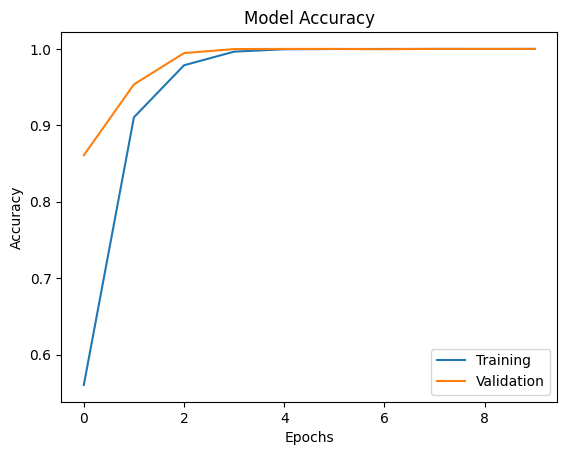

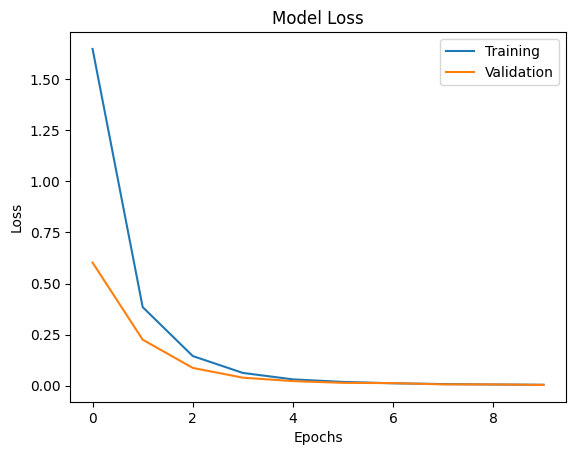

In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

# Step 1: Load Dataset
train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

x_train = train_data.iloc[:, 1:].values
y_train = train_data.iloc[:, 0].values

x_test = test_data.iloc[:, 1:].values
y_test = test_data.iloc[:, 0].values

# Reshape images into 28x28 grayscale format
x_train = x_train.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

# Normalize pixel values
x_train = x_train / 255.0
x_test = x_test / 255.0

# Step 2: Build CNN Model
model = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(25, activation='softmax')
])

# Compile Model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Step 3: Train Model
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

# Step 4: Evaluate Model
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

# Plot Accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['Training', 'Validation'])
plt.show()

# Plot Loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Training', 'Validation'])
plt.show()